<a href="https://colab.research.google.com/github/carlaferraz/HorrorMoviesData/blob/main/HorrorMovieAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Perguntas


1.   Como o número de lançamentos de terror variou por década entre 1950 e 2022, e como mudou a participação de filmes em idiomas diferentes do inglês?
2.   Filmes de terror com maior orçamento recebem avaliações médias maiores do público?
3. Entre os filmes com orçamento e receita informados, os de baixo orçamento apresentam retorno proporcional (receita/orçamento) maior que os de alto orçamento?
4. Quais gêneros aparecem com mais frequência combinados ao terror, e quais combinações têm melhor avaliação e popularidade?
5. Existe concentração de lançamentos em outubro (período do Halloween), e os filmes lançados nesse mês têm popularidade diferente dos demais?
6. Filmes que pertencem a uma franquia têm avaliação e receita diferentes de filmes avulsos?

# Preparacao do Ambiente

In [17]:
!git clone https://github.com/carlaferraz/HorrorMoviesData.git

fatal: destination path 'HorrorMoviesData' already exists and is not an empty directory.


In [18]:
# Bibliotecas para manipulação e visualização dos dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações que deixam os resultados mais legíveis durante a aula
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("✓ Ambiente preparado.")

✓ Ambiente preparado.


# Inicializaçao/ Ingestao

In [19]:
URL_DADOS = "https://raw.githubusercontent.com/carlaferraz/HorrorMoviesData/refs/heads/main/horror_movies.csv"

try:
    df_original = pd.read_csv(URL_DADOS)
except Exception as erro:
    raise RuntimeError(
        "Não foi possível carregar a base. Verifique a conexão com a internet."
    ) from erro

print("✓ Dados carregados com sucesso!")
print(f"Fonte: {URL_DADOS}")
print(f"Shape: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas")
print("\nPrimeiras linhas da base recebida:")
display(df_original.head())

✓ Dados carregados com sucesso!
Fonte: https://raw.githubusercontent.com/carlaferraz/HorrorMoviesData/refs/heads/main/horror_movies.csv
Shape: 32540 linhas × 21 colunas

Primeiras linhas da base recebida:


,Unnamed: 0,id,original_title,title,original_language,overview,tagline,release_date,poster_path,popularity,vote_count,vote_average,budget,revenue,runtime,status,adult,backdrop_path,genre_names,collection,collection_name
0,1,760161,Orphan: First Kill,Orphan: First Kill,en,After escaping from an Estonian psychiatric fa...,There's always been something wrong with Esther.,2022-07-27,/pHkKbIRoCe7zIFvqan9LFSaQAde.jpg,"5,088.58",902,6.90,0.00,"9,572,765.00",99,Released,False,/5GA3vV1aWWHTSDO5eno8V5zDo8r.jpg,"Horror, Thriller","760,193.00",Orphan Collection
1,2,760741,Beast,Beast,en,A recently widowed man and his two teenage dau...,Fight for family.,2022-08-11,/xIGr7UHsKf0URWmyyd5qFMAq4d8.jpg,"2,172.34",584,7.10,0.00,"56,000,000.00",93,Released,False,/2k9tBql5GYH328Krj66tDT9LtFZ.jpg,"Adventure, Drama, Horror",NaN,NaN
2,3,882598,Smile,Smile,en,"After witnessing a bizarre, traumatic incident...","Once you see it, it’s too late.",2022-09-23,/hiaeZKzwsk4y4atFhmncO5KRxeT.jpg,"1,863.63",114,6.80,"17,000,000.00","45,000,000.00",115,Released,False,/mVNPfpydornVe4H4UCIk7WevWjf.jpg,"Horror, Mystery, Thriller",NaN,NaN
3,4,756999,The Black Phone,The Black Phone,en,"Finney Blake, a shy but clever 13-year-old boy...",Never talk to strangers.,2022-06-22,/lr11mCT85T1JanlgjMuhs9nMht4.jpg,"1,071.40",2736,7.90,"18,800,000.00","161,000,000.00",103,Released,False,/AfvIjhDu9p64jKcmohS4hsPG95Q.jpg,"Horror, Thriller",NaN,NaN
4,5,772450,Presencias,Presences,es,A man who loses his wife and goes to seclude h...,NaN,2022-09-07,/dgDT3uol3mdvwEg0jt1ble3l9hw.jpg,"1,021.00",83,7.00,0.00,0.00,0,Released,False,/ojfzhdwRemcDt1I6pao6vVLw9AA.jpg,Horror,NaN,NaN


# Conhecimento

In [20]:
# Dicionário resumido das variáveis mais importantes para a demonstração
dicionario = pd.DataFrame({
    "coluna": [
        "Unnamed: 0", "id", "original_title", "title", "original_language",
        "overview", "tagline", "release_date", "poster_path", "popularity",
        "vote_count", "vote_average", "budget", "revenue", "runtime",
        "status", "adult", "backdrop_path", "genre_names", "collection",
        "collection_name"
    ],
    "significado": [
        "Número de linha do arquivo",
        "ID do filme no TMDB",
        "Título original",
        "Título internacional",
        "Idioma original",
        "Sinopse",
        "Slogan",
        "Data de lançamento",
        "Imagem do pôster",
        "Índice de popularidade",
        "Nº de votos",
        "Nota média (0 a 10)",
        "Orçamento",
        "Receita",
        "Duração (min)",
        "Situação de produção",
        "Conteúdo adulto(eita bixo🔞😳)",
        "Imagem de fundo",
        "Gêneros",
        "ID da coleção/franquia",
        "Nome da coleção/franquia"
    ],
})

display(dicionario.style.hide(axis="index"))

coluna,significado
Unnamed: 0,Número de linha do arquivo
id,ID do filme no TMDB
original_title,Título original
title,Título internacional
original_language,Idioma original
overview,Sinopse
tagline,Slogan
release_date,Data de lançamento
poster_path,Imagem do pôster
popularity,Índice de popularidade


# Inspecionar

A inspeção inicial responde perguntas básicas: qual é o tamanho da base, quais tipos foram inferidos, onde há valores ausentes e como os valores numéricos se distribuem?

Nesta etapa, ainda não alteramos nada.

In [21]:
print("VISÃO GERAL DA BASE ORIGINAL")
print("─" * 50)
print(f"Linhas:  {df_original.shape[0]}")
print(f"Colunas: {df_original.shape[1]}")
print(f"Células: {df_original.shape[0] * df_original.shape[1]:,}")

tipos = df_original.dtypes.astype(str).rename("tipo inferido").to_frame()
tipos.index.name = "coluna"
print("\nTipos inferidos pelo Pandas:")
display(tipos)

VISÃO GERAL DA BASE ORIGINAL
──────────────────────────────────────────────────
Linhas:  32540
Colunas: 21
Células: 683,340

Tipos inferidos pelo Pandas:


,tipo inferido
coluna,
Unnamed: 0,int64
id,int64
original_title,object
title,object
original_language,object
overview,object
tagline,object
release_date,object
poster_path,object


OBS: Blocos a seguir servem para identificar análises de possíveis problemas.
ex: colunas com muitos vazios, valores ausentes...
É importante para observar quais tipos de filtros devemos fazer pra nao quebrar tudo depois (ex: divisao por 0)

VALORES AUSENTES NA BASE ORIGINAL


,quantidade ausente,percentual ausente (%)
collection_name,30234,92.9%
collection,30234,92.9%
tagline,19836,61.0%
backdrop_path,18995,58.4%
poster_path,4474,13.7%
overview,1286,4.0%
original_language,0,0.0%
original_title,0,0.0%
id,0,0.0%
Unnamed: 0,0,0.0%


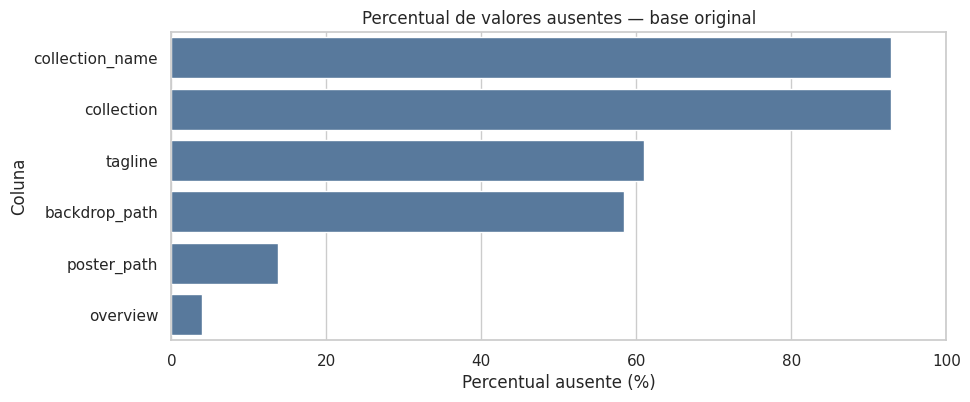

In [22]:
# Quantidade e percentual ajudam a avaliar a dimensão do problema
ausencias = pd.DataFrame({
    "quantidade ausente": df_original.isna().sum(),
    "percentual ausente (%)": df_original.isna().mean().mul(100)
}).sort_values("percentual ausente (%)", ascending=False)

print("VALORES AUSENTES NA BASE ORIGINAL")
display(ausencias.style.format({"percentual ausente (%)": "{:.1f}%"}))

# Mostramos apenas as colunas que realmente possuem ausências
ausencias_grafico = ausencias[ausencias["quantidade ausente"] > 0]
plt.figure(figsize=(10, 4))
sns.barplot(
    data=ausencias_grafico.reset_index(),
    x="percentual ausente (%)", y="index", color="#4C78A8"
)
plt.title("Percentual de valores ausentes — base original")
plt.xlabel("Percentual ausente (%)")
plt.ylabel("Coluna")
plt.xlim(0, 100)
plt.show()

In [23]:
print("ESTATÍSTICAS DAS COLUNAS NUMÉRICAS")
display(df_original.describe().T)

linhas_iguais = int(df_original.duplicated().sum())
print(f"\nLinhas com atributos observados iguais: {linhas_iguais}")
print("⚠ Sem um identificador, não podemos concluir que representam a mesma pessoa.")
print("Verificar e não poder confirmar um problema também é um resultado válido.")

ESTATÍSTICAS DAS COLUNAS NUMÉRICAS


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"32,540.00","16,270.50","9,393.63",1.00,"8,135.75","16,270.50","24,405.25","32,540.00"
id,"32,540.00","445,910.83","305,744.67",17.00,"146,494.75","426,521.00","707,534.00","1,033,095.00"
popularity,"32,540.00",4.01,37.51,0.00,0.60,0.84,2.24,"5,088.58"
vote_count,"32,540.00",62.69,420.89,0.00,0.00,2.00,11.00,"16,900.00"
vote_average,"32,540.00",3.34,2.88,0.00,0.00,4.00,5.70,10.00
budget,"32,540.00","543,126.59","4,542,667.81",0.00,0.00,0.00,0.00,"200,000,000.00"
revenue,"32,540.00","1,349,746.73","14,430,479.15",0.00,0.00,0.00,0.00,"701,842,551.00"
runtime,"32,540.00",62.14,41.00,0.00,14.00,80.00,91.00,683.00
collection,"2,306.00","481,534.88","324,498.16",656.00,"155,421.00","471,259.00","759,067.25","1,033,032.00"



Linhas com atributos observados iguais: 0
⚠ Sem um identificador, não podemos concluir que representam a mesma pessoa.
Verificar e não poder confirmar um problema também é um resultado válido.


O que foi identificado que merece atencao:


1.   release_date como text (deveria ser tipo data)
2.   collection como float (deveria ser tipo text/object)
3. orcamento 0 = nao foi informado, e nao que náo tem
4. os votos nao sao fidedignos, já que 0 significa que ninguém votou. Filmes que possuem nota alta é porque receberam 1 voto que contou como o real
5. ver se nao tem duplicatas mesmo, parece sus




# Decisao

Mastigadinho pra pessoa que for fazer a análise. Bjos

In [24]:
decisoes = pd.DataFrame({
    "problema": [
        "release_date como text",
        "collection como float",
        "orcamento 0 = nao foi informado",
        "os votos nao sao fidedignos",
        "ver se nao tem duplicatas mesmo"
    ],
    "decisão neste exemplo": [
        "release_date deveria ser tipo data",
        "collection deveria ser tipo object",
        "mudar a logica de orcamento, Qual?",
        "mudar logica de voto pra mediana (talvez)",
        "analise de id unico, e nao linha unica"
    ],
    "justificativa resumida": [
        "1",
        "2",
        "3",
        "4",
        "5"
    ]
})

display(decisoes.style.hide(axis="index"))

problema,decisão neste exemplo,justificativa resumida
release_date como text,release_date deveria ser tipo data,1
collection como float,collection deveria ser tipo object,2
orcamento 0 = nao foi informado,"mudar a logica de orcamento, Qual?",3
os votos nao sao fidedignos,mudar logica de voto pra mediana (talvez),4
ver se nao tem duplicatas mesmo,"analise de id unico, e nao linha unica",5
